<a href="https://colab.research.google.com/github/pablo2fp/Modelo-de-previs-o-House-Prices/blob/main/House_Price.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Bibliotecas

In [1]:
%pip install kagglehub[pandas-datasets]

In [ ]:
%pip install shap

In [60]:
#Kagle
import kagglehub
from kagglehub import KaggleDatasetAdapter

#Bibliotecas de manipulação
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import shap

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold
from sklearn.preprocessing import RobustScaler
from sklearn.impute import KNNImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import BatchNormalization

#Dataset

##Conjunto de dados

In [14]:
file_path = "train.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "lespin/house-prices-dataset",
  file_path,
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)


/tmp/ipykernel_7050/2377043976.py:4: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'house-prices-dataset' dataset.


In [15]:
#Visualizar primeiras linhas do dataframe para conferir se todos valores entraram
display(df.head())

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [16]:
#Identificar as variáveis por número de variáveis e tipo de variáveis
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [17]:
#Identificar variáveis com valores nulos
for col in df.columns:
  if df[col].isna().sum() > 0:
    print(f'{col}: {df[col].isna().sum()}')

LotFrontage: 259
Alley: 1369
MasVnrType: 872
MasVnrArea: 8
BsmtQual: 37
BsmtCond: 37
BsmtExposure: 38
BsmtFinType1: 37
BsmtFinType2: 38
Electrical: 1
FireplaceQu: 690
GarageType: 81
GarageYrBlt: 81
GarageFinish: 81
GarageQual: 81
GarageCond: 81
PoolQC: 1453
Fence: 1179
MiscFeature: 1406


In [18]:
#Retirar colunas com número de variáveis muito abaixo do normal
#Variável para colocar as colunas a serem removidas
columns_remover = [
  col for col in df.columns
  if df[col].count() < 1000]

#Visualizar colunas removidas
print(f'Colunas para remover: contagem {len(columns_remover)}, colunas: {columns_remover}')

#Remover colunas
df_filtrado = df.drop(columns = columns_remover)

#Contagem da quantidade de colunas
print(f'Quantidade de colunas restantes: {df_filtrado.shape[1]}')


Colunas para remover: contagem 6, colunas: ['Alley', 'MasVnrType', 'FireplaceQu', 'PoolQC', 'Fence', 'MiscFeature']
Quantidade de colunas restantes: 75


In [19]:
df_filtrado.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [20]:
def coef_vari(df):
  coef = []
  colunas_numericas = []
  #Estrutura de laço para calcular o coeficiente de variação somente nas colunas com valores inteiro ou float
  for col in df.columns:
    if df[col].dtype in ['int64', 'float64']:
      valor = np.std(df[col])/np.mean(df[col])
      coef.append(valor)
      colunas_numericas.append(col)

  #Criar função para analisar o coeficiente de variação da lista do coef
  def analise(valor):
    if valor <= 0.15:
      return 'Baixo'
    elif valor > 0.15 and valor < 0.30:
      return 'Médio'
    else:
      return 'Alto'

  #Aplicar a função de análise para criar uma lista
  analise_resultados = [analise(c) for c in coef]

  #Criando dataframe para melhor visualização
  coef_df = pd.DataFrame({'Coluna': colunas_numericas, 'Coeficiente de Variação': coef, 'Analise': analise_resultados})
  display(coef_df)

  # Agrupar por 'Analise' e contar a quantidade de colunas em cada classificação
  print("\nQuantidade de colunas por classificação de variação:")
  display(coef_df.groupby('Analise')[['Coluna']].count())

coef_vari(df_filtrado)

,Coluna,Coeficiente de Variação,Analise
0,Id,0.576955,Alto
1,MSSubClass,0.743201,Alto
2,LotFrontage,0.346533,Alto
3,LotArea,0.948751,Alto
4,OverallQual,0.226669,Médio
5,OverallCond,0.199525,Médio
6,YearBuilt,0.015316,Baixo
7,YearRemodAdd,0.010398,Baixo
8,MasVnrArea,1.745705,Alto
9,BsmtFinSF1,1.027730,Alto



Quantidade de colunas por classificação de variação:


,Coluna
Analise,
Alto,29
Baixo,4
Médio,5


In [21]:
#Como houve 29 colunas com alto coeficiente de variação, para preencher as colunas que contém valores nulos será utilizado transformação RobustScaler e KNNimputer para calcular o valor de vizinhos próximos e preencher
from sklearn.impute import KNNImputer
from sklearn.preprocessing import RobustScaler

# Separar as colunas numéricas de df_filtrado
colunas_numericas = df_filtrado.select_dtypes(include=['int64', 'float64']).columns
colunas_categoricas = df_filtrado.select_dtypes(exclude=['int64', 'float64']).columns

df_num = df_filtrado[colunas_numericas]
df_categ = df_filtrado[colunas_categoricas]

# Instanciar os transformadores
scaler_robust = RobustScaler()
imputer = KNNImputer(n_neighbors=5)

# Aplicar a escala e a imputação apenas nas colunas numéricas
df_scaler = scaler_robust.fit_transform(df_num)
df_imputer = imputer.fit_transform(df_scaler)

# Desfazer a escala para voltar aos valores originais preenchidos
df_num_final = pd.DataFrame(scaler_robust.inverse_transform(df_imputer), columns=colunas_numericas)

# Preenncher colunas categoricas
df_categ_final = df_categ.fillna(df_categ.mode().iloc[0])

# Identificar colunas categóricas para juntá-las de volta ao DataFrame final
df_preenchido = df_num_final.join(df_categ_final.reset_index(drop=True))

display(df_preenchido.head())

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,Electrical,KitchenQual,Functional,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,SaleType,SaleCondition
0,1.0,60.0,65.0,8450.0,7.0,5.0,2003.0,2003.0,196.0,706.0,...,SBrkr,Gd,Typ,Attchd,RFn,TA,TA,Y,WD,Normal
1,2.0,20.0,80.0,9600.0,6.0,8.0,1976.0,1976.0,0.0,978.0,...,SBrkr,TA,Typ,Attchd,RFn,TA,TA,Y,WD,Normal
2,3.0,60.0,68.0,11250.0,7.0,5.0,2001.0,2002.0,162.0,486.0,...,SBrkr,Gd,Typ,Attchd,RFn,TA,TA,Y,WD,Normal
3,4.0,70.0,60.0,9550.0,7.0,5.0,1915.0,1970.0,0.0,216.0,...,SBrkr,Gd,Typ,Detchd,Unf,TA,TA,Y,WD,Abnorml
4,5.0,60.0,84.0,14260.0,8.0,5.0,2000.0,2000.0,350.0,655.0,...,SBrkr,Gd,Typ,Attchd,RFn,TA,TA,Y,WD,Normal


In [22]:
# Conferir se todos os dados foram preenchidos
df_preenchido.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 75 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   float64
 1   MSSubClass     1460 non-null   float64
 2   LotFrontage    1460 non-null   float64
 3   LotArea        1460 non-null   float64
 4   OverallQual    1460 non-null   float64
 5   OverallCond    1460 non-null   float64
 6   YearBuilt      1460 non-null   float64
 7   YearRemodAdd   1460 non-null   float64
 8   MasVnrArea     1460 non-null   float64
 9   BsmtFinSF1     1460 non-null   float64
 10  BsmtFinSF2     1460 non-null   float64
 11  BsmtUnfSF      1460 non-null   float64
 12  TotalBsmtSF    1460 non-null   float64
 13  1stFlrSF       1460 non-null   float64
 14  2ndFlrSF       1460 non-null   float64
 15  LowQualFinSF   1460 non-null   float64
 16  GrLivArea      1460 non-null   float64
 17  BsmtFullBath   1460 non-null   float64
 18  BsmtHalf

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


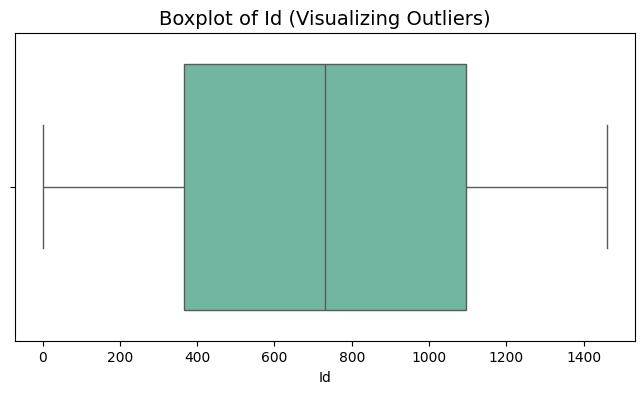

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


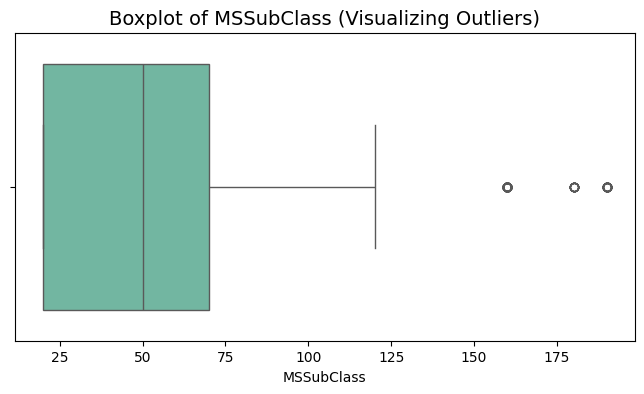

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


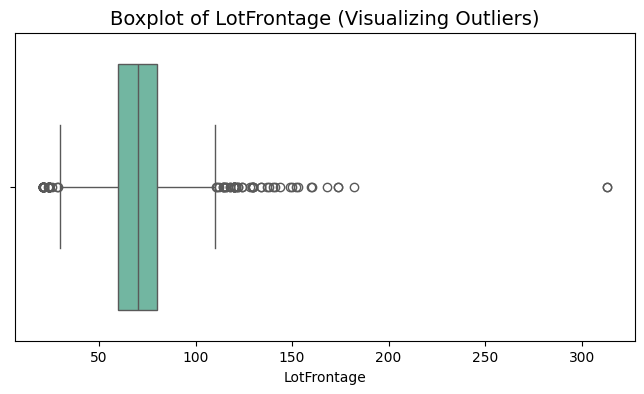

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


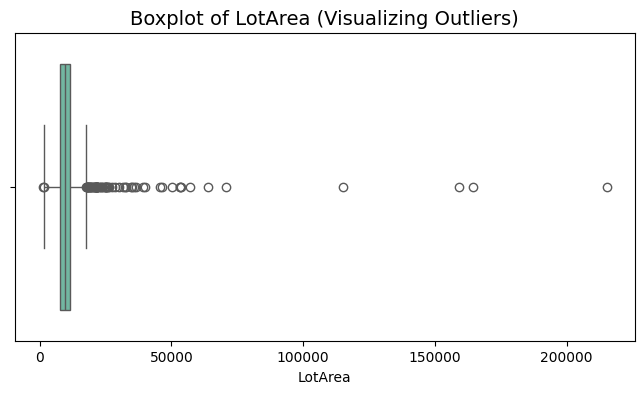

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


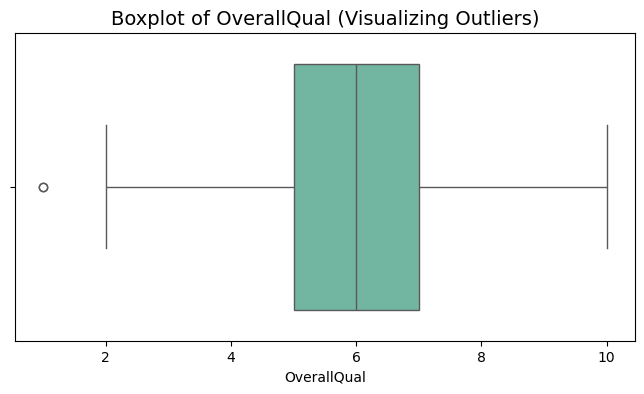

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


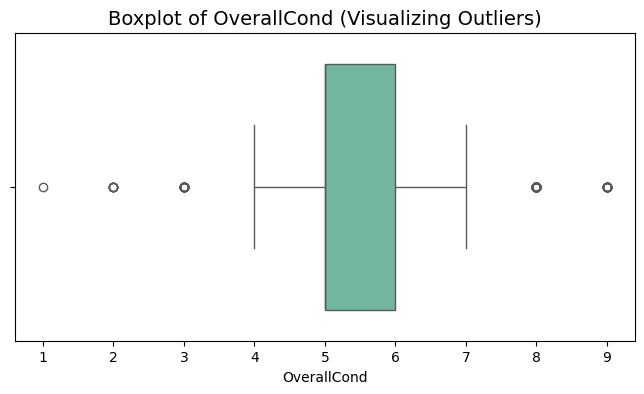

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


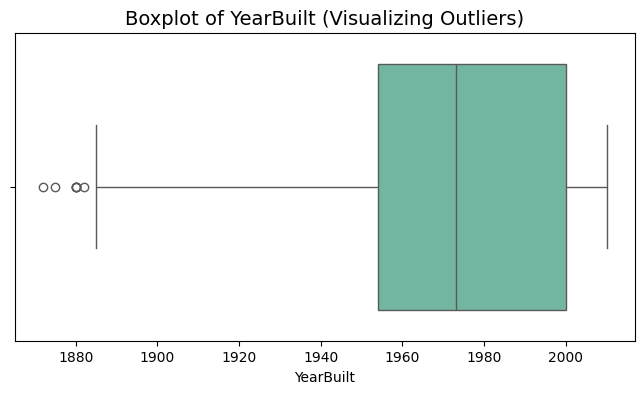

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


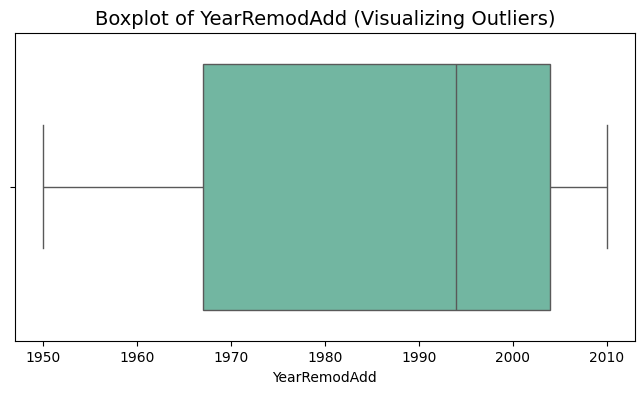

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


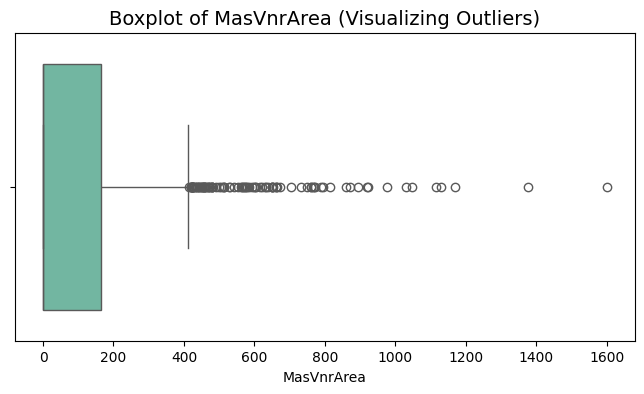

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


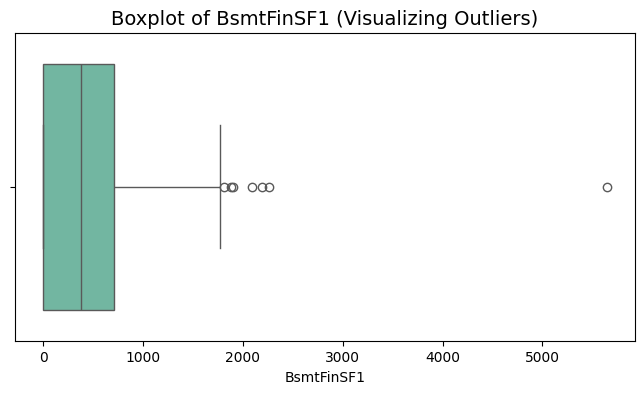

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


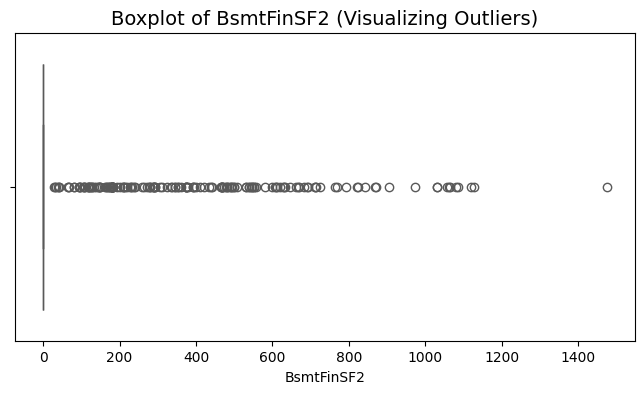

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


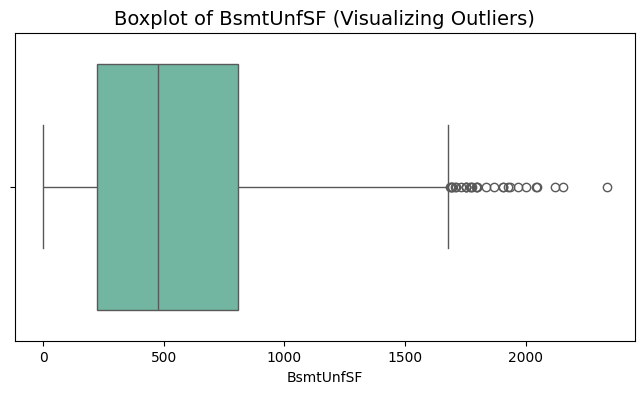

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


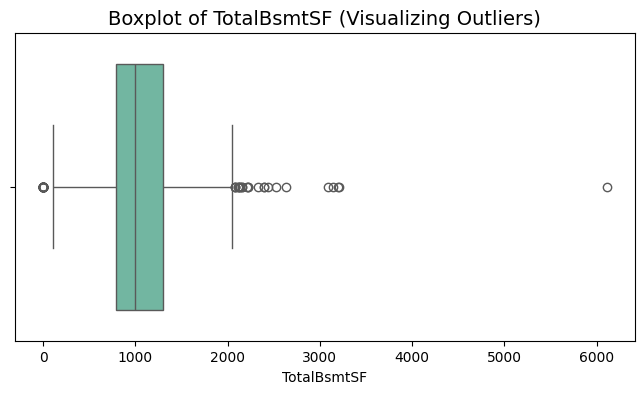

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


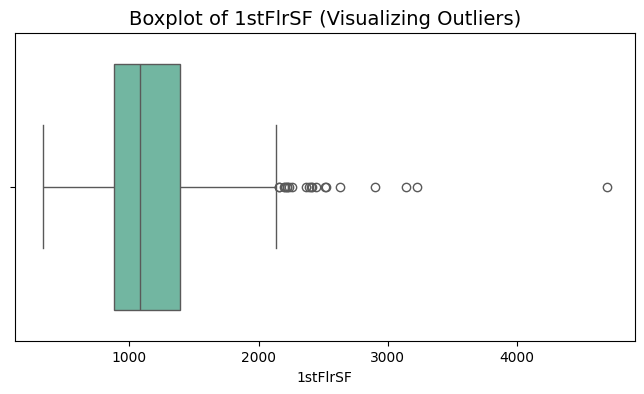

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


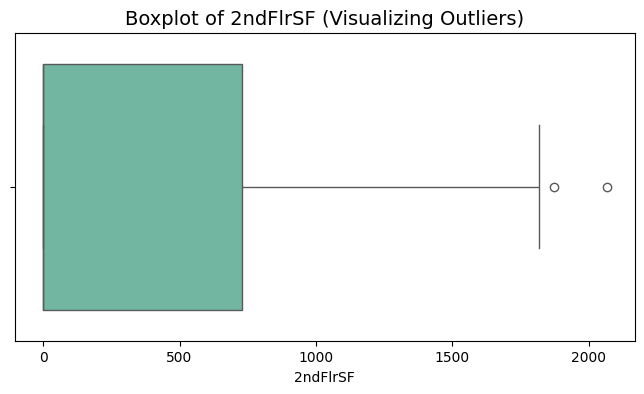

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


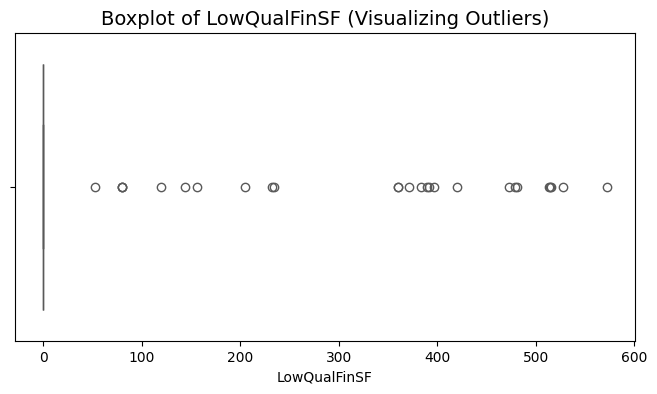

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


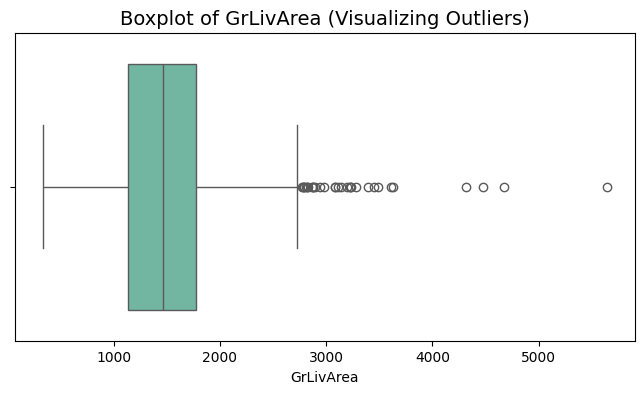

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


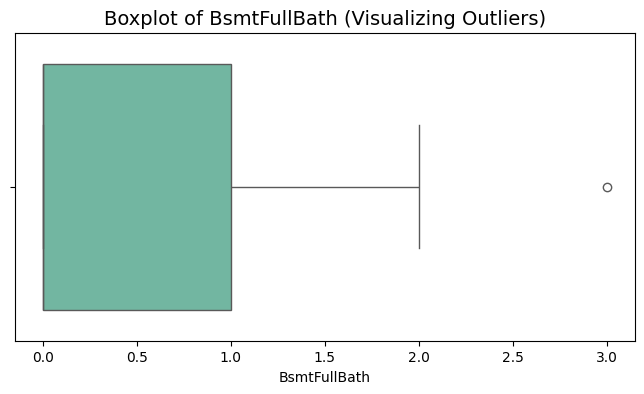

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


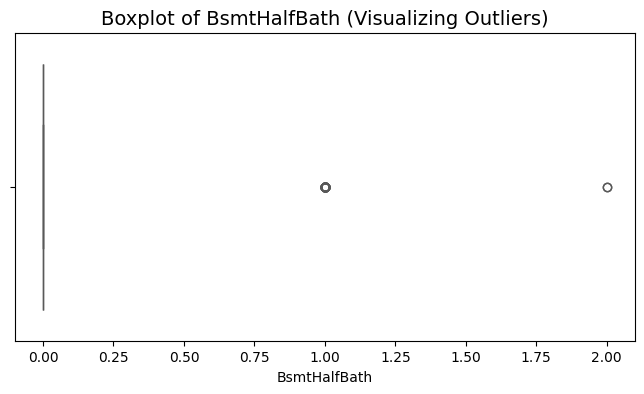

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


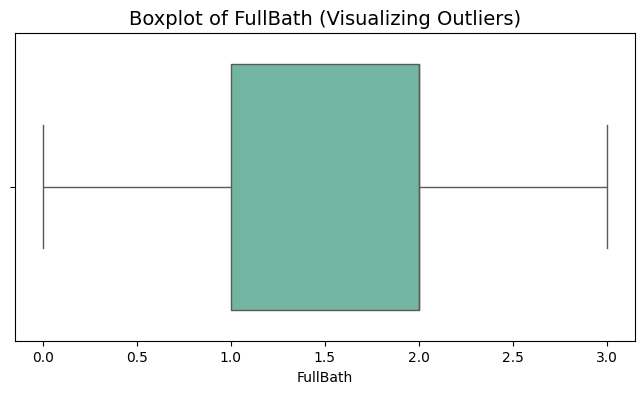

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


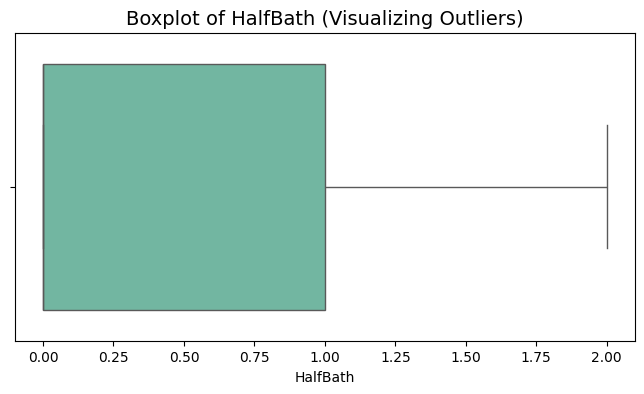

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


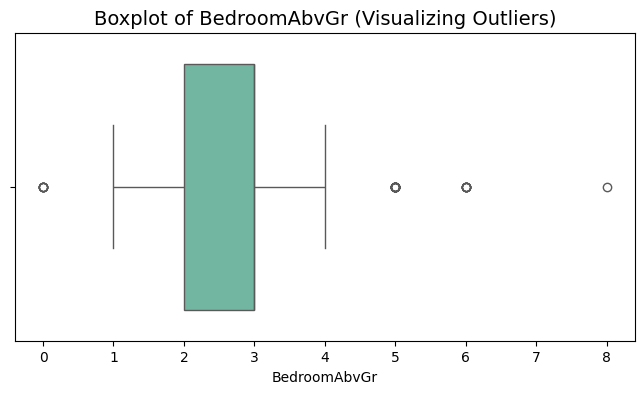

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


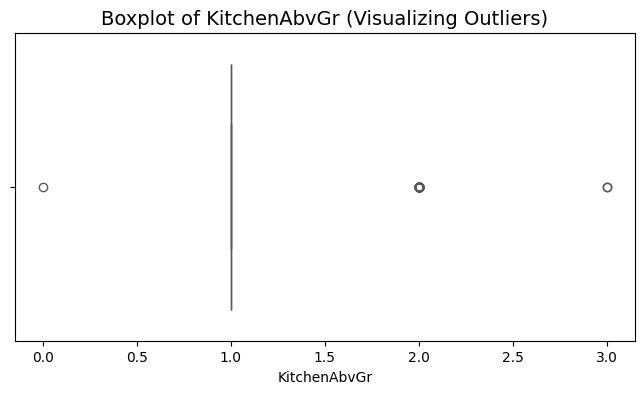

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


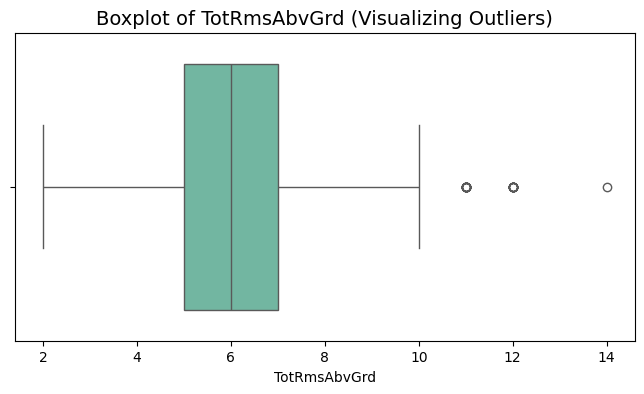

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


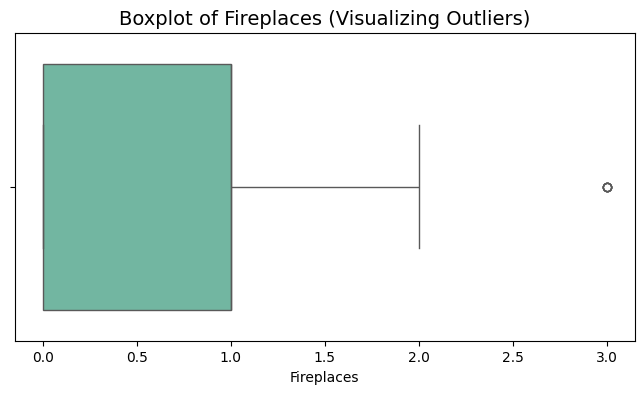

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


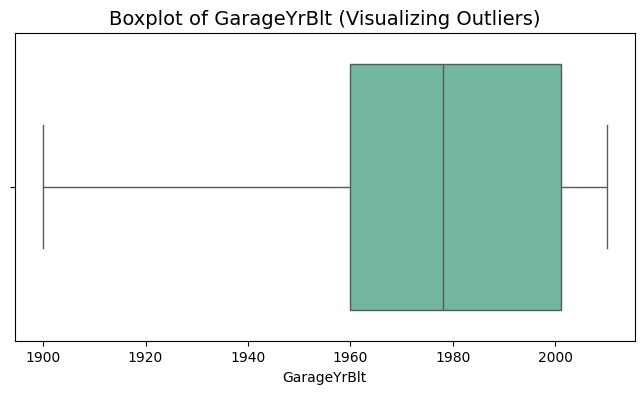

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


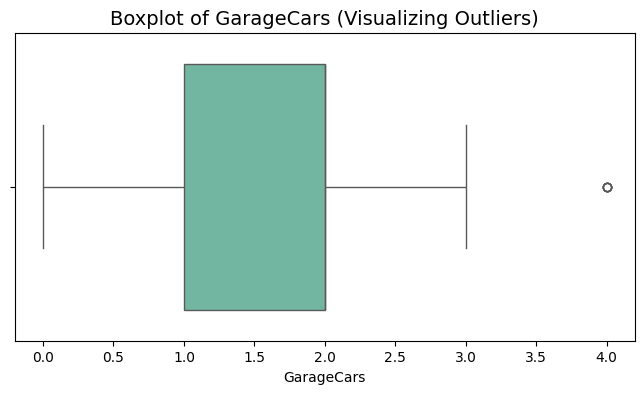

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


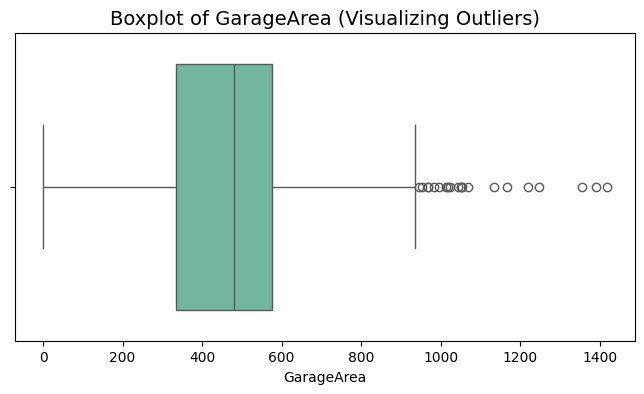

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


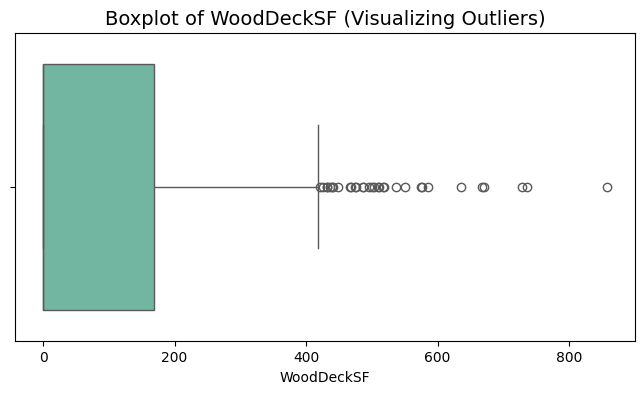

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


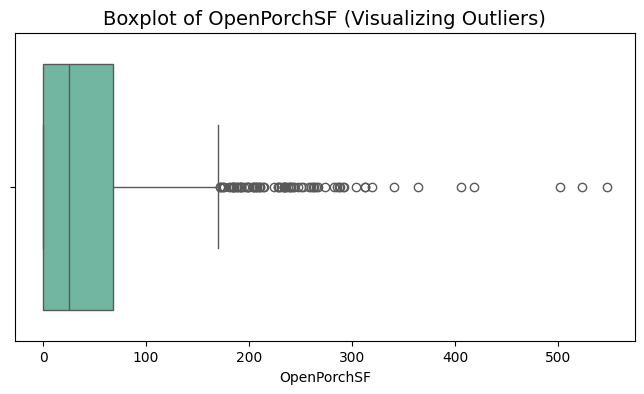

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


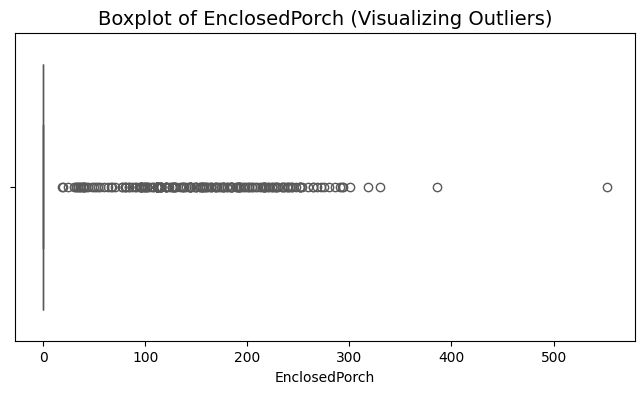

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


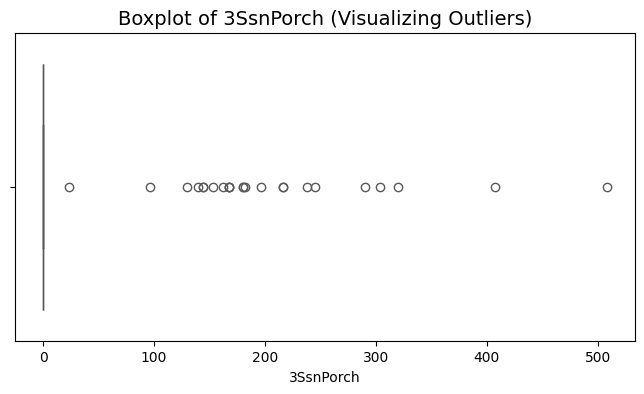

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


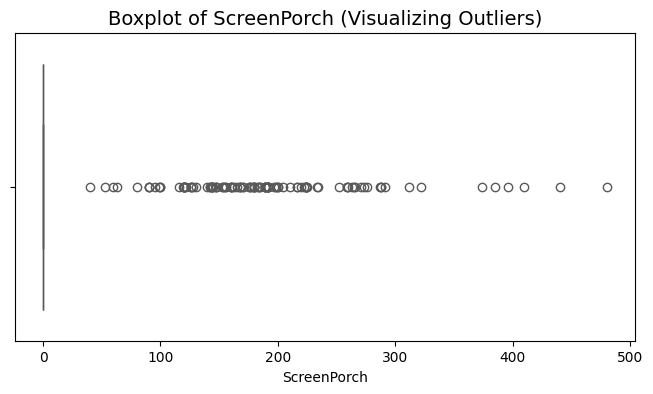

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


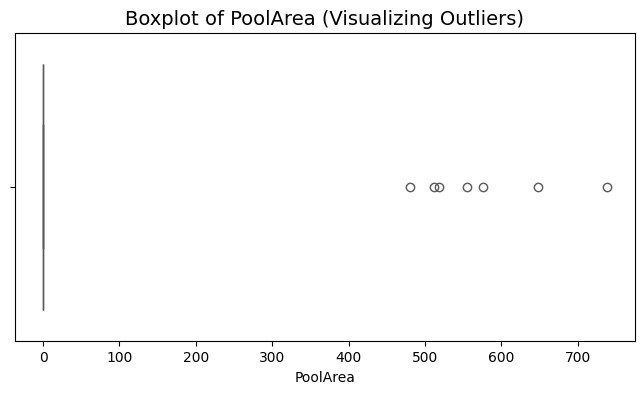

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


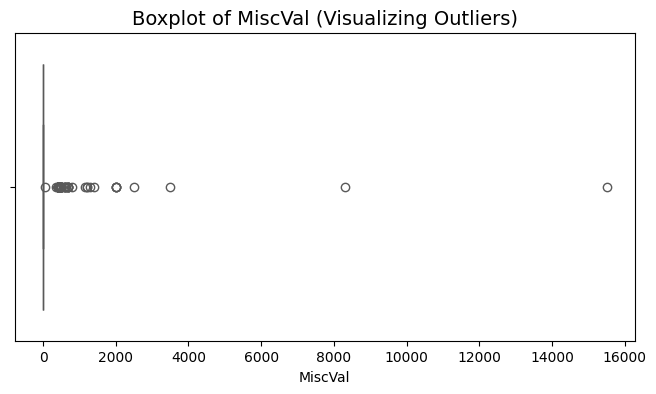

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


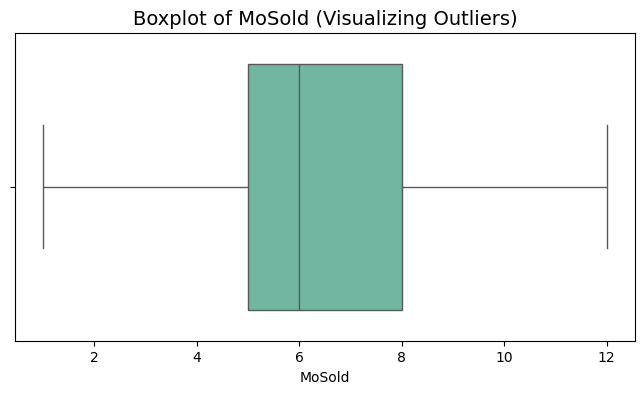

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


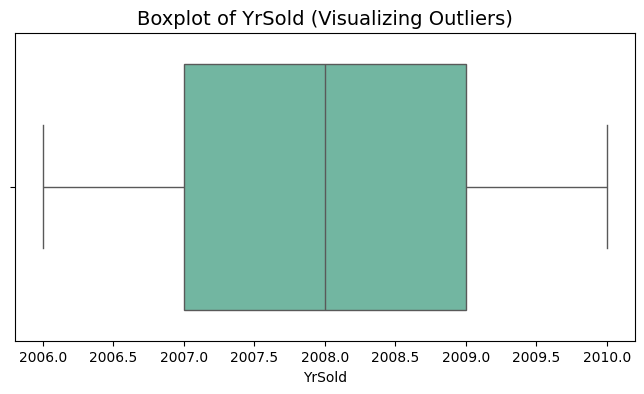

/tmp/ipykernel_7050/239491943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_preenchido, x=col, palette="Set2")


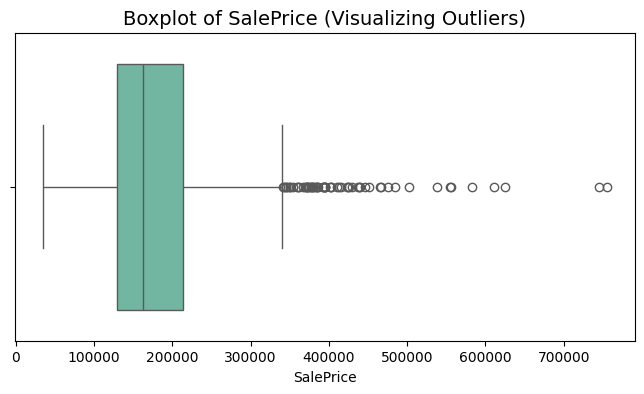

In [23]:
# Plotar um boxplot para encontrar outliers
for col in df_preenchido.select_dtypes(include="number").columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df_preenchido, x=col, palette="Set2")
    plt.title(f"Boxplot of {col} (Visualizing Outliers)", fontsize=14)
    plt.show()

In [24]:
# Remover outlieres de colunas
# 1. Selecionar colunas númericas
numerical_cols = df_preenchido.select_dtypes(include=['int64', 'float64']).columns

# Criar função para remover outlier (baseada em um notebook do Kagle)
def handle_outliers_iqr(dataframe, cols):
    for col in cols:
        # Calcular Q1, Q3, e IQR para cada coluna
        Q1 = dataframe[col].quantile(0.25)
        Q3 = dataframe[col].quantile(0.75)
        IQR = Q3 - Q1

        # Calcular o maior e menor valor
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Demonstrar o numéro de ouliers antes de remover
        print(f"{col}: Outliers Before Handling = {(dataframe[col] < lower_bound).sum() + (dataframe[col] > upper_bound).sum()}")

        # # Opção 1: Remover outliers
        # dataframe = dataframe[(dataframe[col] >= lower_bound) & (dataframe[col] <= upper_bound)]

        # Opção 2: Limitar os valores discrepantes aos valores limite
        dataframe[col] = dataframe[col].clip(lower=lower_bound, upper=upper_bound)

        # Demonstrar o numéro de ouliers após remover
        print(f"{col}: Outliers After Handling = {(dataframe[col] < lower_bound).sum() + (dataframe[col] > upper_bound).sum()}\n")

    return dataframe

df_cleaned = handle_outliers_iqr(df_preenchido, numerical_cols)

Id: Outliers Before Handling = 0
Id: Outliers After Handling = 0

MSSubClass: Outliers Before Handling = 103
MSSubClass: Outliers After Handling = 0

LotFrontage: Outliers Before Handling = 97
LotFrontage: Outliers After Handling = 0

LotArea: Outliers Before Handling = 69
LotArea: Outliers After Handling = 0

OverallQual: Outliers Before Handling = 2
OverallQual: Outliers After Handling = 0

OverallCond: Outliers Before Handling = 125
OverallCond: Outliers After Handling = 0

YearBuilt: Outliers Before Handling = 7
YearBuilt: Outliers After Handling = 0

YearRemodAdd: Outliers Before Handling = 0
YearRemodAdd: Outliers After Handling = 0

MasVnrArea: Outliers Before Handling = 97
MasVnrArea: Outliers After Handling = 0

BsmtFinSF1: Outliers Before Handling = 7
BsmtFinSF1: Outliers After Handling = 0

BsmtFinSF2: Outliers Before Handling = 167
BsmtFinSF2: Outliers After Handling = 0

BsmtUnfSF: Outliers Before Handling = 29
BsmtUnfSF: Outliers After Handling = 0

TotalBsmtSF: Outliers 

In [25]:
from sklearn.preprocessing import OneHotEncoder
# 1. Encontrar as colunas categóricas automaticamente (tipo 'object' ou 'category')
colunas_categoricas = df_cleaned.select_dtypes(include=['object', 'category']).columns
print(colunas_categoricas)

# 2. Instanciar o encoder
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

# 3. Ajustar e transformar apenas as colunas categóricas
encoded_array = encoder.fit_transform(df_cleaned[colunas_categoricas])

# 4. Pegar os novos nomes das colunas criadas
novas_colunas = encoder.get_feature_names_out(colunas_categoricas)

# 5. Criar o DataFrame com o resultado do encoding
df_encoded = pd.DataFrame(encoded_array, columns=novas_colunas, dtype=int)

# 6. Remover as colunas antigas e juntar as novas colunas ao DataFrame original
df_final = df_cleaned.drop(columns=colunas_categoricas).join(df_encoded)

display(df_final)

Index(['MSZoning', 'Street', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional',
       'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive',
       'SaleType', 'SaleCondition'],
      dtype='object')


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,1.0,60.0,65.0,8450.0,7.0,5.0,2003.0,2003.0,196.0,7.060000e+02,...,0,0,0,1,0,0,0,0,1,0
1,2.0,20.0,80.0,9600.0,6.0,7.5,1976.0,1976.0,0.0,9.780000e+02,...,0,0,0,1,0,0,0,0,1,0
2,3.0,60.0,68.0,11250.0,7.0,5.0,2001.0,2002.0,162.0,4.860000e+02,...,0,0,0,1,0,0,0,0,1,0
3,4.0,70.0,60.0,9550.0,7.0,5.0,1915.0,1970.0,0.0,2.160000e+02,...,0,0,0,1,1,0,0,0,0,0
4,5.0,60.0,84.0,14260.0,8.0,5.0,2000.0,2000.0,350.0,6.550000e+02,...,0,0,0,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456.0,60.0,62.0,7917.0,6.0,5.0,1999.0,2000.0,0.0,-5.684342e-14,...,0,0,0,1,0,0,0,0,1,0
1456,1457.0,20.0,85.0,13175.0,6.0,6.0,1978.0,1988.0,119.0,7.900000e+02,...,0,0,0,1,0,0,0,0,1,0
1457,1458.0,70.0,66.0,9042.0,7.0,7.5,1941.0,2006.0,0.0,2.750000e+02,...,0,0,0,1,0,0,0,0,1,0
1458,1459.0,20.0,68.0,9717.0,5.0,6.0,1950.0,1996.0,0.0,4.900000e+01,...,0,0,0,1,0,0,0,0,1,0


In [26]:
#Separação em x e y
x = df_final.drop(columns = ['SalePrice', 'Id'])
y = df_final['SalePrice']

##Divisão dos dados

In [27]:
#Chamar a função train_test split para dividir os dados em treino e teste
x_train, x_test, y_train, y_test = sklearn.model_selection.train_test_split(x, y, test_size=0.2, random_state=42)
print(f'Formato X_train: {x_train.shape}')
print(f'Formato X_test: {x_test.shape}')
print(f'Formato y_train: {y_train.shape}')
print(f'Formato y_test: {y_test.shape}')

Formato X_train: (1168, 266)
Formato X_test: (292, 266)
Formato y_train: (1168,)
Formato y_test: (292,)


In [28]:
#Nesse passo, as variáveis de treino e teste serão escalonadas. Esse passo é essêncial para padronizar os valores das variáveis e evitar vicio na máquina.

#Criar variável para escalonar os valores de X
scaler_x = StandardScaler()

#Aplicar fit somente nos dados de treino
x_scaler_train = scaler_x.fit_transform(x_train)
#Na variável x_test deve-se aplicar somente a transformação
x_scaler_test = scaler_x.transform(x_test)

#Criar variável para escalonar os valores de y
scaler_y = StandardScaler()
#Y_train
y_train_scaler = scaler_y.fit_transform(y_train.values.reshape(-1, 1))
#Y_test
y_test_scaler = scaler_y.transform(y_test.values.reshape(-1, 1))

#Modelos
Nessa seção será treinado os modelos com as variáveis x_train_scaled e y_train_scaled. Após o treino, o modelo será avaliado com as variáveis x_test_scaled e y_test_scaled. Essas variáveis não são utilizadas durante o treino, portanto, o modelo não aprendeu com elas, assim, as métricas avaliadas terão uma melhor interpretação.
Modelos de previsões utilização regressão para prever respostas futuras. Nesse tipo de modelo as métricas utilizadas são: erro médio absoluto, erro médio quadrado, raiz do erro médio quadrado e o r2.

#Modelo Neural

O modelo neural foi utilizado para comparar com modelos mais clássicos. Esse modelo utiliza camadas de neurônios na entrada dos dados e utiliza a backpropagation para encontrar o melhor resultado. Durante o treino, o modelo avalia o resultado de acordo com uma métrica. Para o modelo em questão foi escolhida a métrica de erro médio absoluto (mae).

In [95]:
model = Sequential([
    Dense(128, activation='relu', input_shape=(x_scaler_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.4),
    Dense(1, activation='linear')
])

# Compilar o modelo corrigindo o nome do loss e passando metrics como lista
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mean_squared_error',
    metrics=['mae']
)

early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)

# Correção do posicionamento e passagem de parâmetros do early_stopping
history = model.fit(x_scaler_train, y_train_scaler, epochs=100, validation_split=0.2, callbacks=[early_stopping])

Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 2.1762 - mae: 1.1087 - val_loss: 0.6863 - val_mae: 0.6004
Epoch 2/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 1.3282 - mae: 0.8536 - val_loss: 0.4117 - val_mae: 0.4714
Epoch 3/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.9886 - mae: 0.7625 - val_loss: 0.3869 - val_mae: 0.4672
Epoch 4/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.9150 - mae: 0.7143 - val_loss: 0.3070 - val_mae: 0.4162
Epoch 5/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.8221 - mae: 0.6629 - val_loss: 0.2698 - val_mae: 0.3893
Epoch 6/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.7344 - mae: 0.6292 - val_loss: 0.2672 - val_mae: 0.3862
Epoch 7/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.6098 - mae: 0.5661 - val_loss: 0.2430 - val_mae: 0.3591
Epoch 8/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.5053 - mae: 0.5266 - val_loss: 0.2119 - val_mae: 0.3389
Epoch 9/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.4413 - m

In [99]:
y_test_original = scaler_y.inverse_transform(y_test_scaler)
y_pred = model.predict(x_scaler_test)
y_pred_original = scaler_y.inverse_transform(y_pred.reshape(-1, 1))

#metricas extras de avaliação
mae_neural = mean_absolute_error(y_test_original, y_pred_original)
mse_neural = mean_squared_error(y_test_original, y_pred_original)
rmse_neural = np.sqrt(mse_neural)
r2_neural = r2_score(y_test_original, y_pred_original)

print('Métricas na Escala Original (R$ / $):')
print(f'MAE: {mae_neural:.2f}')
print(f'MSE: {mse_neural:.2f}')
print(f'RMSE: {rmse_neural:.2f}')
print(f'R2: {r2_neural*100:.2f}')

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Métricas na Escala Original (R$ / $):
MAE: 14895.44
MSE: 445101391.32
RMSE: 21097.43
R2: 90.90


# Modelo Support Vector Machine

In [103]:
svr = SVR(kernel='poly', C=10, epsilon = 0.0001)
svr.fit(x_scaler_train, y_train_scaler)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR(C=10, epsilon=0.0001, kernel='poly')

In [104]:
y_test_original = scaler_y.inverse_transform(y_test_scaler)
y_pred = svr.predict(x_scaler_test)
y_pred_original = scaler_y.inverse_transform(y_pred.reshape(-1, 1))

mae_svr = mean_absolute_error(y_test_original, y_pred_original)
mse_svr = mean_squared_error(y_test_original, y_pred_original)
rmse_svr = np.sqrt(mse_svr)
r2_svr = r2_score(y_test_original, y_pred_original)

print('Métricas na Escala Original (R$ / $):')
print(f'MAE: {mae_svr:.2f}')
print(f'MSE: {mse_svr:.2f}')
print(f'RMSE: {rmse_svr:.2f}')
print(f'R2: {r2_svr*100:.2f}')

Métricas na Escala Original (R$ / $):
MAE original: 16209.59
MSE original: 560444406.65
RMSE original: 20957.79
R2: 88.54


#Modelo Random Forest

In [57]:
rand = RandomForestRegressor(max_depth=8, n_estimators = 400, random_state=42)
rand.fit(x_scaler_train, y_train_scaler)

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


RandomForestRegressor(max_depth=8, n_estimators=400, random_state=42)

In [105]:
y_test_original = scaler_y.inverse_transform(y_test_scaler)
y_pred = rand.predict(x_scaler_test)
y_pred_original = scaler_y.inverse_transform(y_pred.reshape(-1, 1))

mae_rand = mean_absolute_error(y_test_original, y_pred_original)
mse_rand = mean_squared_error(y_test_original, y_pred_original)
rmse_rand = np.sqrt(mse_rand)
r2_rand = r2_score(y_test_original, y_pred_original)

print('Métricas na Escala Original (R$ / $):')
print(f'MAE original: {mae_rand:.2f}')
print(f'MSE original: {mse_rand:.2f}')
print(f'RMSE original: {rmse_rand:.2f}')
print(f'R2: {r2_rand*100:.2f}')

Métricas na Escala Original (R$ / $):
MAE original: 15343.84
MSE original: 439228753.89
RMSE original: 20957.79
R2: 91.02


#Comparação dos modelos

Nesta seção será avaliado o desempenho total dos modelos. Para isso, foram criados gráficos de dispersão, uma tabela comparativa. A escolha do melhor modelo será com base no R2. O melhor modelo será analisado quanto ao peso de cada variável para melhor interpretação.

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


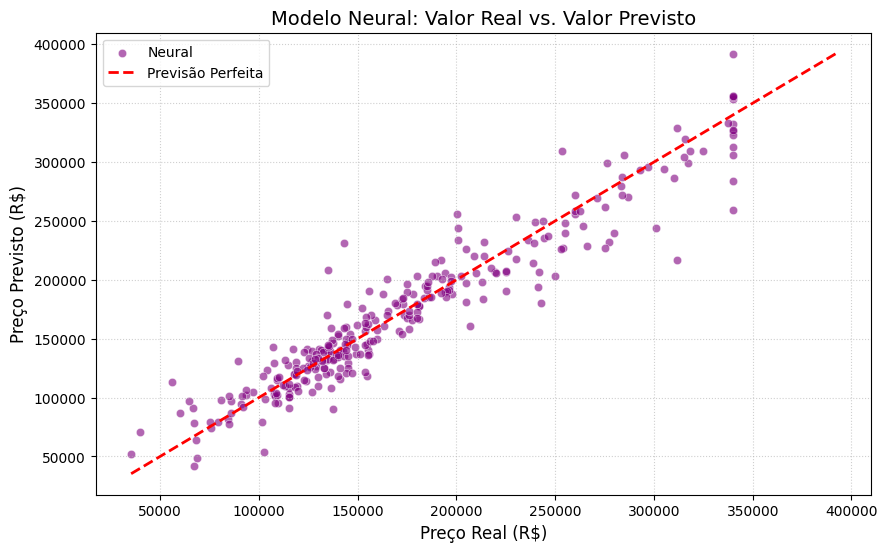

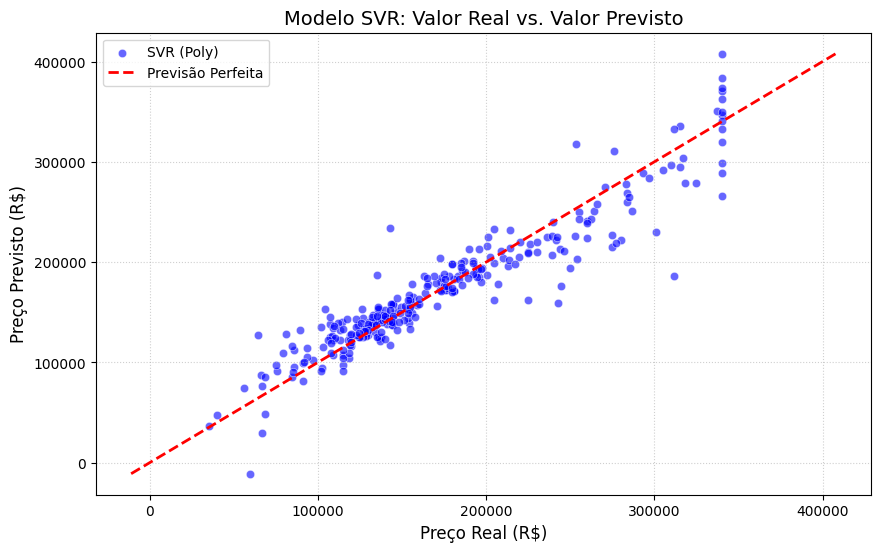

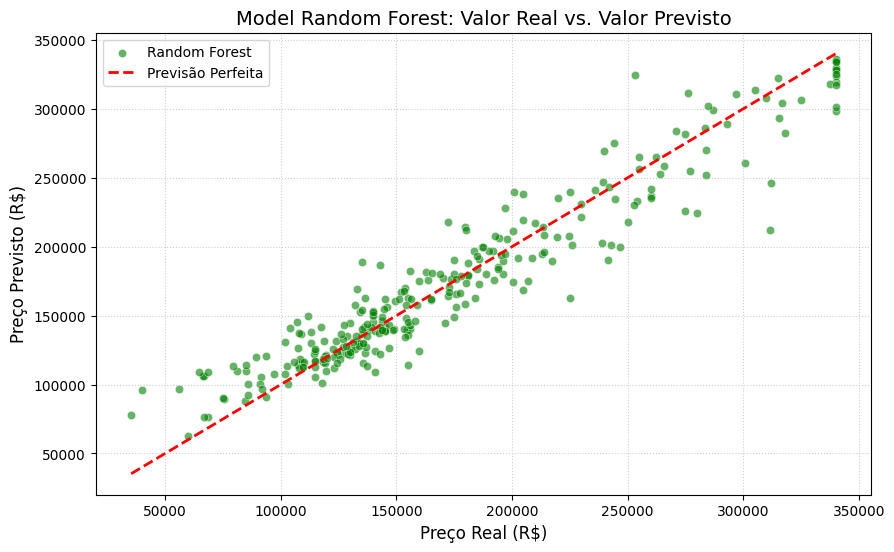

In [112]:
# Criando a figura Neural
neural_plot = plt.figure(figsize=(10, 6))

# Gráfico de dispersão para o SVR
y_pred_neural_orig = scaler_y.inverse_transform(model.predict(x_scaler_test).reshape(-1, 1))
svr_sns = sns.scatterplot(x=y_test_original.ravel(), y=y_pred_neural_orig.ravel(), alpha=0.6, label='Neural', color='purple')

# Linha de Identidade (Previsão Perfeita: y = x)
lims_neural = [
    min(y_test_original.min(), y_pred_neural_orig.min()),
    max(y_test_original.max(), y_pred_neural_orig.max())
]
plt.plot(lims_neural, lims_neural, color='red', linestyle='--', linewidth=2, label='Previsão Perfeita')

plt.title('Modelo Neural: Valor Real vs. Valor Previsto', fontsize=14)
plt.xlabel('Preço Real (R$)', fontsize=12)
plt.ylabel('Preço Previsto (R$)', fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# Criando a figura SVR
svr_plot = plt.figure(figsize=(10, 6))

# Gráfico de dispersão para o SVR
y_pred_svr_orig = scaler_y.inverse_transform(svr.predict(x_scaler_test).reshape(-1, 1))
svr_sns = sns.scatterplot(x=y_test_original.ravel(), y=y_pred_svr_orig.ravel(), alpha=0.6, label='SVR (Poly)', color='blue')

# Linha de Identidade (Previsão Perfeita: y = x)
lims_svr = [
    min(y_test_original.min(), y_pred_svr_orig.min()),
    max(y_test_original.max(), y_pred_svr_orig.max())
]
plt.plot(lims_svr, lims_svr, color='red', linestyle='--', linewidth=2, label='Previsão Perfeita')

plt.title('Modelo SVR: Valor Real vs. Valor Previsto', fontsize=14)
plt.xlabel('Preço Real (R$)', fontsize=12)
plt.ylabel('Preço Previsto (R$)', fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# Criando a figura Rand
rand_plot = plt.figure(figsize=(10, 6))
# Gráfico de dispersão para o Random Forest
y_pred_rand_orig = scaler_y.inverse_transform(rand.predict(x_scaler_test).reshape(-1, 1))
rand_sns = sns.scatterplot(x=y_test_original.ravel(), y=y_pred_rand_orig.ravel(), alpha=0.6, label='Random Forest', color='green')

# Linha de Identidade (Previsão Perfeita: y = x)
lims = [
    min(y_test_original.min(), y_pred_rand_orig.min()),
    max(y_test_original.max(), y_pred_rand_orig.max())
]
plt.plot(lims, lims, color='red', linestyle='--', linewidth=2, label='Previsão Perfeita')

plt.title('Model Random Forest: Valor Real vs. Valor Previsto', fontsize=14)
plt.xlabel('Preço Real (R$)', fontsize=12)
plt.ylabel('Preço Previsto (R$)', fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

O modelo SVR apresentou menor dispersão em análise gráfica. O modelo Neural e Rand tiveram maior dispersão, porém, entre os dois, o modelo neural apresentou mais dispersão.

In [113]:
modelos_df = pd.DataFrame({
    'Modelo': ['Neural', 'SVR', 'Random Forest'],
    'MAE': [mae_neural, mae_svr, mae_rand],
    'MSE': [mse_neural, mse_svr, mse_rand],
    'RMSE': [rmse_neural, rmse_svr, rmse_rand],
    'R2': [r2_neural, r2_svr, r2_rand]
})

modelos_df['R2'] = modelos_df['R2'].apply(lambda x: f'{x*100:.2f}%')

display(modelos_df)

,Modelo,MAE,MSE,RMSE,R2
0,Neural,14895.442008,4.451014e+08,21097.426178,90.90%
1,SVR,16209.587594,5.604444e+08,20957.785043,88.54%
2,Random Forest,15343.844866,4.392288e+08,20957.785043,91.02%


De acordo com a tabela, o modelo com maior R2 foi o modelo Random Forest. Assim, o modelo será utilizado para prever dados. Além disso, será analisado as principais variáveis que contribuiram para o aprendizado do modelo.

##Interpretabilidade do modelo

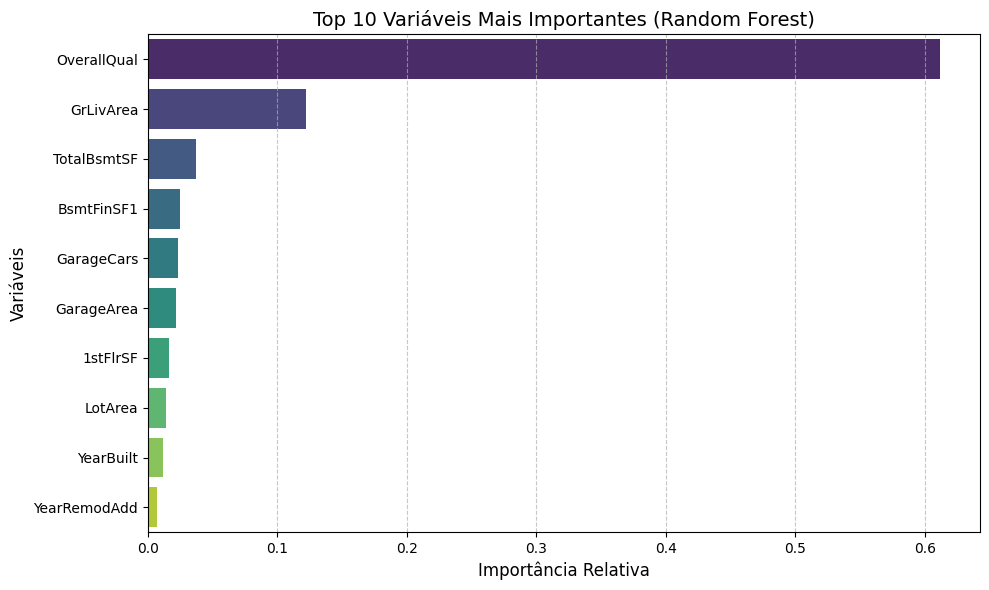

In [121]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Mapear a importância com o nome correspondente das colunas
importancias = pd.Series(rand.feature_importances_, index=x.columns)

# 2. Selecionar as 10 variáveis mais importantes
top_10_importancias = importancias.sort_values(ascending=False).head(10)

# 3. Plotar as variáveis em um gráfico de barras horizontal
plt.figure(figsize=(10, 6))
sns.barplot(x=top_10_importancias.values, y=top_10_importancias.index, palette='viridis', hue=top_10_importancias.index, legend=False)

plt.title('Top 10 Variáveis Mais Importantes (Random Forest)', fontsize=14)
plt.xlabel('Importância Relativa', fontsize=12)
plt.ylabel('Variáveis', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

O gráfico acima apresenta as 10 variáveis mais importantes de acordo com a importância relativa. É necessário ressaltar que a variável OverallQual que significa a qualidade geral do imóvel (acabamento, estrutura, etc) tem maior impacto do modelo, representando cerca de 60% da importância de decisões do modelo. A segunda variável mais importante é a GrLivArea que significa a área útitl do imóvel, com 12% de importância. Com essas duas variáveis é possível deduzir que para previsão de preço de um imóvel, quanto melhor a qualidade e maior a área, maior o preço. Outras variáveis como garagem, presença de porão, área de primeiro andar, lote e ano de construção e reforma também impactam no modelo.

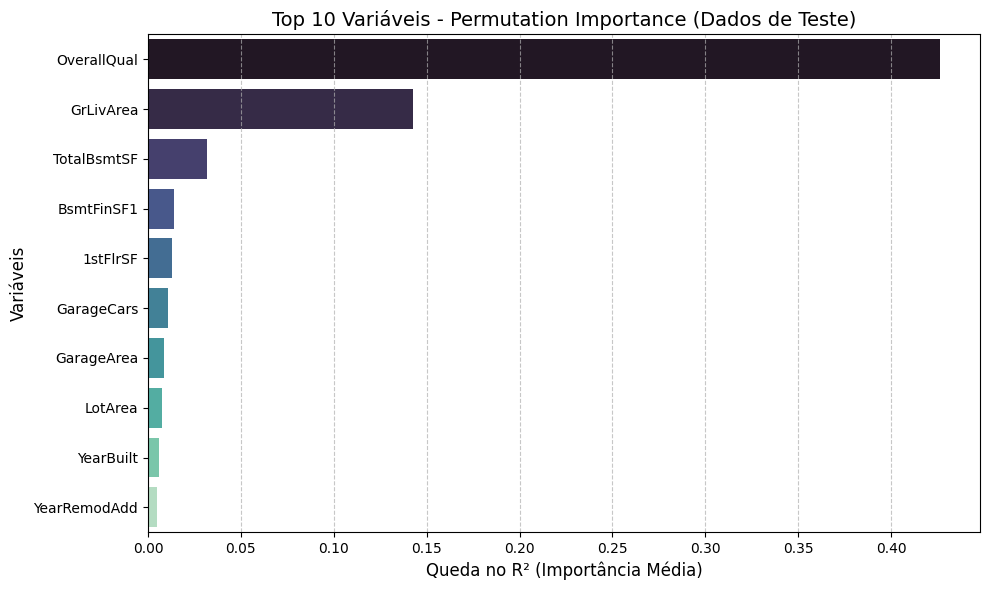

In [122]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calcular a importância por permutação nos dados de teste
# Usamos n_repeats=10 para repetir o embaralhamento 10 vezes e obter uma média estável
resultado_perm = permutation_importance(
    estimator=rand,
    X=x_scaler_test,
    y=y_test_scaler,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# 2. Criar uma Series com as médias das importâncias mapeadas para as colunas originais
importancias_perm = pd.Series(resultado_perm.importances_mean, index=x.columns)

# 3. Selecionar as 10 principais variáveis
top_10_perm = importancias_perm.sort_values(ascending=False).head(10)

# 4. Plotar o gráfico
plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_10_perm.values,
    y=top_10_perm.index,
    palette='mako',
    hue=top_10_perm.index,
    legend=False
)

plt.title('Top 10 Variáveis - Permutation Importance (Dados de Teste)', fontsize=14)
plt.xlabel('Queda no R² (Importância Média)', fontsize=12)
plt.ylabel('Variáveis', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Para avaliação das top 10 variáveis foi realizada a permutação que é uma técnica que consiste em misturar os valores das variáveis de forma aleatória e treinar o modelo para avaliar o impacto em uma métrica escolhida. No caso, a métrica foi R2. Embaralhando a variável OverallQual é possível observar uma queda de 42% no valor do R2, ou seja, isso consolida a importância dessa variável para o modelo.

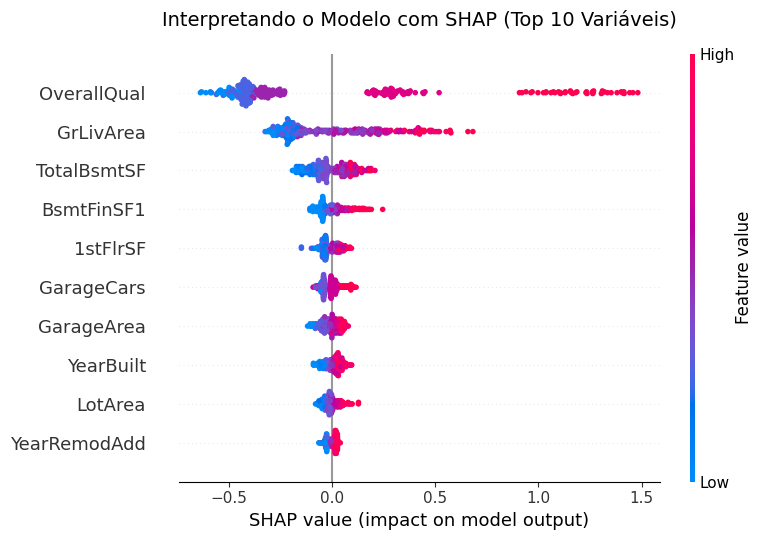

In [126]:
# 1. Instanciar o TreeExplainer (específico para modelos baseados em árvores como Random Forest)
explainer = shap.TreeExplainer(rand)

# 2. Calcular os SHAP values para os dados de teste escalonados
# Como o Random Forest foi treinado com x_scaler_test, usamos ele aqui
shap_values = explainer.shap_values(x_scaler_test)

# 3. Gerar o gráfico de sumário explicativo (Beeswarm Plot)
# Usaremos os nomes das colunas originais (x.columns) para facilitar a leitura
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, x_scaler_test, feature_names=x.columns, max_display=10, show=False)
plt.title('Interpretando o Modelo com SHAP (Top 10 Variáveis)', fontsize=14, pad=20)
plt.tight_layout()
plt.show()

Por fim, foi realizado a SHAP para avaliação final das variáveis de maior impacto do modelo. A SHAP é uma técnica que consiste em avaliar o impacto do valor da variável na decisão do modelo. Aplicando a técnica, foi possível observar:
1. OverallQual (Qualidade Geral): Ter uma qualidade geral alta (pontos vermelhos à direita) eleva drasticamente o preço do imóvel (impacto positivo de até +1.5 unidades padrão). Inversamente, qualidades baixas (pontos azuis à esquerda) puxam o valor para baixo de forma muito acentuada.

2. GrLivArea (Área Útil): Áreas maiores (vermelho) valorizam significativamente o imóvel. Áreas pequenas (azul) desvalorizam, mas de forma mais contida comparado à qualidade geral.

3. TotalBsmtSF (Área do Porão) & BsmtFinSF1: Áreas maiores de porão ou acabamento de porão mostram uma clara tendência de valorização (pontos vermelhos concentrados à direita).

4. YearBuilt (Ano de Construção) & YearRemodAdd: Imóveis mais novos ou reformados recentemente (pontos vermelhos) geram impacto positivo no preço final.

# Aplicação Prática: Prevendo o preço de um novo imóvel

Após analisar as métricas, foi criado um modelo que incorpore somente as 10 variáveis de maior importância.

### Criando e Treinando o Modelo com as Top 10 Features

In [127]:
# 1. Definir as 10 variáveis mais importantes
top_10_features = list(top_10_importancias.index)
print("As 10 variáveis selecionadas:", top_10_features)

# 2. Filtrar os conjuntos originais de treino e teste (antes do escalonamento)
x_train_top10 = x_train[top_10_features]
x_test_top10 = x_test[top_10_features]

# 3. Criar e ajustar o scaler de features exclusivo para as 10 colunas
scaler_x_top10 = StandardScaler()
x_train_scaled_top10 = scaler_x_top10.fit_transform(x_train_top10)
x_test_scaled_top10 = scaler_x_top10.transform(x_test_top10)

# 4. Treinar o novo modelo Random Forest com a mesma configuração
rand_simplificado = RandomForestRegressor(max_depth=8, n_estimators=400, random_state=42)
rand_simplificado.fit(x_train_scaled_top10, y_train_scaler.ravel())

# 5. Avaliar o modelo simplificado
y_pred_scaled = rand_simplificado.predict(x_test_scaled_top10)
y_pred_original = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1))

mae_simplificado = mean_absolute_error(y_test_original, y_pred_original)
r2_simplificado = r2_score(y_test_original, y_pred_original)

print('\nComparação de Performance:')
print(f'Modelo Completo (266 features) -> R²: {r2_rand*100:.2f}% | MAE: R$ {mae_rand:.2f}')
print(f'Modelo Simplificado (10 features) -> R²: {r2_simplificado*100:.2f}% | MAE: R$ {mae_simplificado:.2f}')

As 10 variáveis selecionadas: ['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'BsmtFinSF1', 'GarageCars', 'GarageArea', '1stFlrSF', 'LotArea', 'YearBuilt', 'YearRemodAdd']

Comparação de Performance:
Modelo Completo (266 features) -> R²: 91.02% | MAE: R$ 15343.84
Modelo Simplificado (10 features) -> R²: 89.96% | MAE: R$ 16065.85


Comparando os modelos com as features completas (266 features) e o modelo novo proposto (10 features), observa-se uma perca de apenas 1% no R2 e um ganho de r$ 722,00 no MAE, indicando pouca alteração entre os modelos e mostrando que as 10 features utuilizadas tem alto impacto no modelo.

### Nova Função Simplificada de Predição para Produção

Assim, foi construido uma função para aplicar o modelo. A função consiste em receber os valores das 10 variáveis e com isso utilizar o modelo para prever o valor final.

In [128]:
def prever_imovel_simplificado(dados_imovel_dict, scaler_x_10, scaler_y_original, modelo_simplificado, features_esperadas):
    """
    Realiza a previsão recebendo apenas as 10 variáveis obrigatórias em formato de dicionário.
    Ideal para APIs, formulários web ou aplicativos mobile.
    """
    # Converter dicionário para DataFrame
    df_novo = pd.DataFrame([dados_imovel_dict])

    # Garantir a ordem exata das colunas
    df_novo = df_novo[features_esperadas]

    # Escalonar os dados utilizando o scaler de 10 dimensões
    dados_scaled = scaler_x_10.transform(df_novo)

    # Fazer a predição
    pred_scaled = modelo_simplificado.predict(dados_scaled)

    # Desfazer o escalonamento do preço de saída
    pred_original = scaler_y_original.inverse_transform(pred_scaled.reshape(-1, 1))

    return float(pred_original[0][0])

# --- Exemplo de Aplicação Prática ---
# Vamos criar o perfil de um imóvel informando apenas as 10 variáveis obrigatórias
exemplo_novo_imovel = {
    'OverallQual': 7.0,     # Qualidade geral (escala de 1 a 10)
    'GrLivArea': 1710.0,    # Área útil acima do solo (pés quadrados)
    'TotalBsmtSF': 856.0,   # Área total do porão
    'BsmtFinSF1': 706.0,    # Área de porão concluída tipo 1
    'GarageCars': 2.0,      # Capacidade de carros na garagem
    'GarageArea': 548.0,    # Área total da garagem
    '1stFlrSF': 856.0,      # Área do 1º andar
    'LotArea': 8450.0,      # Área total do terreno
    'YearBuilt': 2003.0,    # Ano de construção
    'YearRemodAdd': 2003.0  # Ano de reforma
}

valor_previsto = prever_imovel_simplificado(
    dados_imovel_dict=exemplo_novo_imovel,
    scaler_x_10=scaler_x_top10,
    scaler_y_original=scaler_y,
    modelo_simplificado=rand_simplificado,
    features_esperadas=top_10_features
)

print(f"Valor estimado do imóvel: ${valor_previsto:,.2f}")

Valor estimado do imóvel: $201,649.44


A nova função prever_imovel_simplificado recebeu apenas os parâmetros essenciais em formato de dicionário e retornou instantaneamente a previsão: $201,649.44.

Essa arquitetura simplificada agora é ideal para colocar o modelo em produção (ex: integrá-lo a um site, aplicativo de celular ou planilha), dispensando One-Hot Encoding manual e tratamentos de nulos de centenas de colunas secundárias!